In [1]:
import os
os.environ.pop("DEBUG", None)
from pathlib import Path

import sys
sys.path.append(str(Path.cwd().parent))

from datetime import datetime
import shutil
from hydromt_sfincs import SfincsModel, utils
from hydromt._utils import log
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from python.twl_boundary import *

c:\Users\adrie\anaconda3\envs\hydromt-sfincs\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# root folder
PROJECT_FOLDER = Path.cwd().parent
MODEL_FOLDER = Path.cwd().parent / 'model'
yml_path = PROJECT_FOLDER / 'data_catalog.yml'
DATA_FOLDER = PROJECT_FOLDER / 'data'


In [ ]:
# input
model_root = MODEL_FOLDER / "jakarta_base"
# region = DATA_FOLDER/ 'geojson/jkt_bay_1.geojson'
use_subgrid = False


In [ ]:
# Add file handler to log to a file
log_file = Path(model_root) / "hydromt_sfincs.log"
logger = log._add_filehandler(log_file)

# Initialize SfincsModel Python class with the artifact data catalog which contains publically available data for North Italy
sf = SfincsModel(
    data_libs=yml_path,  # specify which data libraries to use
    root=model_root,  # specify the root directory for the model
    mode="r+",  # specify the mode for opening the model (r=read only, r+=append, w=write, w+=overwrite
    write_gis=True,  # specify whether to write GIS data
)

sf.read()

2026-11-27 11:11:58,635 - hydromt.data_catalog.data_catalog - data_catalog - INFO - Parsing data catalog from f:\BTP Work\2026\ews-pantura\data_catalog.yml
2026-11-27 11:11:59,078 - hydromt.model.model - model - INFO - Initializing sfincs model from hydromt_sfincs (v2.0.0rc1).
2026-11-27 11:11:59,080 - hydromt.model.model - model - WARNING - No region component found in components.
2026-11-27 11:11:59,488 - hydromt.model.components.grid - grid - WARNING - Replacing grid map: mask
2026-11-27 11:11:59,490 - hydromt.model.components.grid - grid - WARNING - Replacing grid map: dep
2026-11-27 11:11:59,493 - hydromt.model.components.grid - grid - WARNING - Replacing grid map: manning
2026-11-27 11:11:59,654 - hydromt.hydromt_sfincs.components.output - output - WARNING - File F:\BTP Work\2026\ews-pantura\model\jakarta_base\sfincs_map.nc not found.
2026-11-27 11:11:59,656 - hydromt.hydromt_sfincs.components.output - output - WARNING - File F:\BTP Work\2026\ews-pantura\model\jakarta_base\sfincs

In [ ]:
twl_df = pd.read_parquet('twl.parquet')
surge_df = pd.read_parquet('surge.parquet')
tide_df = twl_df - surge_df

In [ ]:
RP = 100
percentile = 0.999
nhour=36
make_plot = False
dt = 600
trim_data = True


tide_df = tide_df.asfreq(f"{dt}s").interpolate(method="time")
surge_df = surge_df.asfreq(f"{dt}s").interpolate(method="time")


ts_average = []
ts_spring = []
for col in twl_df.keys():
# for tidepd, surgepd in zip()    

    print(f'Extreme value analysis for boundary {col}')
    RPs = eva_POT(twl_df[col], RP, percentile, make_plot=make_plot)

    average_tide_signal, spring_tide_signal=generate_tide_signals(tide_df[col],make_plot=make_plot)
    surge_hydrograph_height, surge_hydrograph_duration_mean = generate_surge_hydrograph(surge_df[col],percentile,make_plot=make_plot)
    storm_tide_hydrograph_average_tide_signal,storm_tide_hydrograph_spring_tide_signal = generate_storm_tide_hydrograph(
        average_tide_signal,spring_tide_signal,surge_hydrograph_duration_mean,surge_hydrograph_height,
        RP,RPs,make_plot=make_plot)
    
    if trim_data:
        storm_tide_hydrograph_average_tide_signal = trim_timeseries(storm_tide_hydrograph_average_tide_signal,nhour=nhour,dt=dt)
        storm_tide_hydrograph_spring_tide_signal = trim_timeseries(storm_tide_hydrograph_average_tide_signal,nhour=nhour,dt=dt)


    ts_average.append(storm_tide_hydrograph_average_tide_signal)
    ts_spring.append(storm_tide_hydrograph_spring_tide_signal)

    # bzs.append(ts)

Extreme value analysis for boundary 0
Threshold = 0.89 m
Number of peaks = 211
Number of event per year Ns = 2.81
RMSE GPD = 0.003
Extreme value analysis for boundary 1
Threshold = 0.896 m
Number of peaks = 217
Number of event per year Ns = 2.89
RMSE GPD = 0.003
Extreme value analysis for boundary 2
Threshold = 0.894 m
Number of peaks = 222
Number of event per year Ns = 2.96
RMSE GPD = 0.003
Extreme value analysis for boundary 3
Threshold = 0.88 m
Number of peaks = 224
Number of event per year Ns = 2.99
RMSE GPD = 0.003
Extreme value analysis for boundary 4
Threshold = 0.871 m
Number of peaks = 221
Number of event per year Ns = 2.95
RMSE GPD = 0.003


In [ ]:
bzs = np.column_stack(ts_spring)
t = np.arange(0,bzs.shape[0]*dt,dt)
bzs = np.column_stack([t,bzs])

print('Saving bzs file.....')
bzs_files = os.path.join(model_root,'twl.bzs')
np.savetxt(bzs_files,bzs,delimiter='\t',fmt="%.6f")

Saving bzs file.....


2026-11-27 14:28:23,717 - hydromt.hydromt_sfincs.components.config.config - config - INFO - Updating 3 attributes in model config.
2026-11-27 14:28:23,753 - hydromt.data_catalog.data_catalog - data_catalog - INFO - Parsing data catalog from f:\BTP Work\2026\ews-pantura\data_catalog.yml


2026-11-27 14:28:23,836 - hydromt.model.model - model - INFO - Initializing sfincs model from hydromt_sfincs (v2.0.0rc1).
2026-11-27 14:28:23,838 - hydromt.model.model - model - WARNING - No region component found in components.
2026-11-27 14:28:26,202 - hydromt.hydromt_sfincs.components.forcing.boundary_conditions - boundary_conditions - INFO - Removed 5 duplicate points based on 'name' or geometry.


(<Figure size 600x428.571 with 2 Axes>,
 <GeoAxes: title={'center': 'SFINCS dep map'}, xlabel='x [m] - WGS 84 / UTM zone 48S', ylabel='y [m]'>)

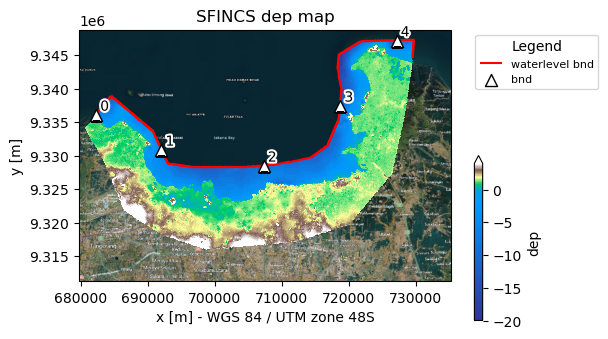

In [ ]:
# Change period of model simulation time, specified in yyyymmdd HHMMSS, to match with the available water level data
sf.config.update(
    {
        "tref": datetime(2026, 10, 5),
        "tstart": datetime(2026, 10, 5),
        "tstop": datetime(2026, 10, 7),
    }
)

# From geodataset
# sf.water_level.create(geodataset="gtsmv3_eu_era5")

# sf.discharge_points.add_point(
#     x=436189, y=9237197, value=1000.0, name="Tide?"
# )
# read and modify bc
# bzs_files = r'f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\twl.bzs'
wl = sf.water_level.read_boundary_conditions_timeseries(bzs_files)
wl.index = pd.to_datetime(wl.index).astype("datetime64[ns]")
sf.water_level.create(timeseries=wl,locations=sf.water_level.gdf)
# sf.write()

# # create bc internally
# sf.water_level.create_timeseries(
#     # index=[0],
#     shape="sine",
#     amplitude = 1.5,
#     phase = 0.0,
#     period = 43200.0,
# )


# and plot
sf.plot_basemap(
    variable="dep", plot_geoms=True, plot_bounds=True, bmap="sat", zoomlevel=12
)
sf.plot_forcing()